In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (7043, 21)


In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [ ]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [ ]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [ ]:
df['gender'].value_counts()

gender
Male      3555
Female    3488
Name: count, dtype: int64

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

print("Unique customers:", df["customerID"].nunique())

Duplicate rows: 0
Unique customers: 7043


In [ ]:
df.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [ ]:
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts().head(10))


customerID
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
9305-CDSKC    1
1452-KIOVK    1
6713-OKOMC    1
7892-POOKP    1
6388-TABGU    1
Name: count, dtype: int64

gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Na

C:\Users\sharv\AppData\Local\Temp\ipykernel_14864\2695330914.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


In [ ]:
print("TotalCharges data type:")
print(df["TotalCharges"].dtype)

print("\nBlank TotalCharges:")
print((df["TotalCharges"].astype(str).str.strip() == "").sum())

TotalCharges data type:
str

Blank TotalCharges:
11


In [ ]:
blank_rows = df[
    df["TotalCharges"].astype(str).str.strip() == ""
]

blank_rows[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Unique customer IDs:", df["customerID"].nunique())
print("Total records:", len(df))

Duplicate rows: 0
Unique customer IDs: 7043
Total records: 7043


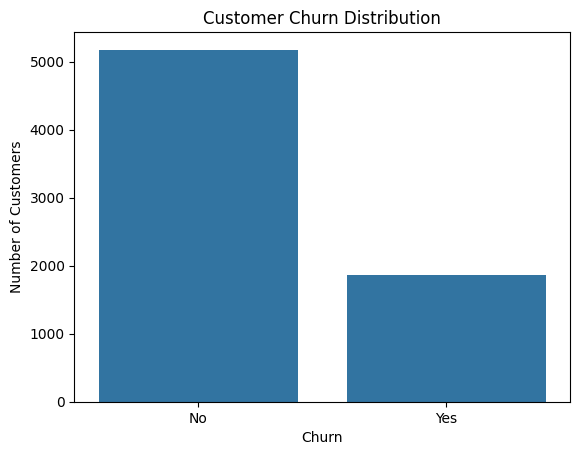

In [ ]:
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

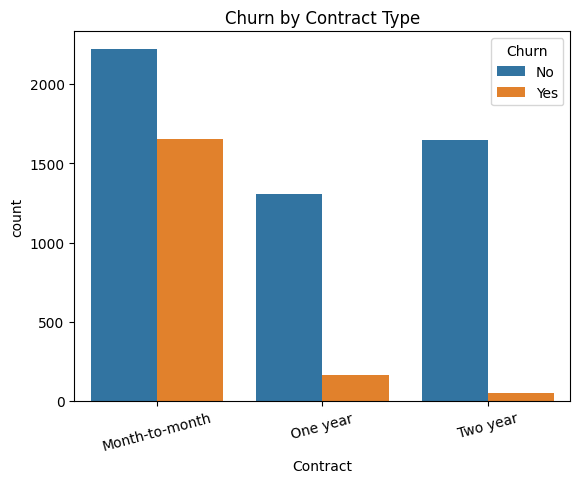

In [ ]:
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.xticks(rotation=15)
plt.show()

In [ ]:
# Create a copy of the original dataset
clean_df = df.copy()

# Convert TotalCharges from string to numeric
clean_df["TotalCharges"] = pd.to_numeric(
    clean_df["TotalCharges"],
    errors="coerce"
)

# Check missing values after conversion
print("Missing values after conversion:")
print(clean_df["TotalCharges"].isnull().sum())

Missing values after conversion:
11


In [ ]:
clean_df["TotalCharges"] = clean_df["TotalCharges"].fillna(0)

print("Missing values after cleaning:")
print(clean_df.isnull().sum().sum())

Missing values after cleaning:
0


In [ ]:
clean_df = clean_df.drop(columns=["customerID"])

print("Original shape:", df.shape)
print("Cleaned shape:", clean_df.shape)

Original shape: (7043, 21)
Cleaned shape: (7043, 20)


In [ ]:
clean_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

In [ ]:
clean_df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
X = clean_df.drop(columns=["Churn"])
y = clean_df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [ ]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [ ]:
numeric_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [ ]:
from sklearn.linear_model import LogisticRegression

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Complete ML pipeline created!")

Complete ML pipeline created!


In [ ]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
y_pred = model.predict(X_test)

print("Predictions generated!")
print(y_pred[:20])

Predictions generated!
[0 1 0 1 0 1 1 0 0 1 1 0 0 1 0 0 0 1 0 0]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

Accuracy: 0.7381
Precision: 0.5043
Recall: 0.7834
F1 Score: 0.6136


In [ ]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"]
))

              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



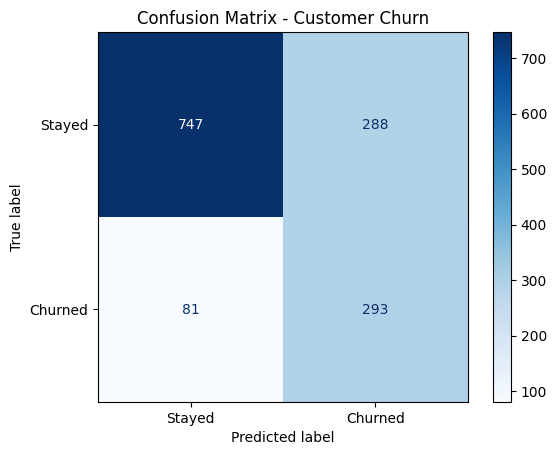

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Customer Churn")
plt.show()

ROC-AUC Score: 0.8416


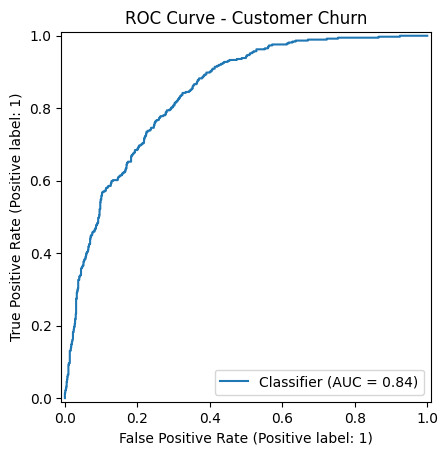

In [ ]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

y_prob = model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", round(auc, 4))

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve - Customer Churn")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model training data:", X_fit.shape)
print("Validation data:", X_val.shape)

Model training data: (4507, 19)
Validation data: (1127, 19)


In [ ]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [ ]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created!")

Random Forest pipeline created!


In [ ]:
rf_model.fit(X_fit, y_fit)

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
y_val_pred = rf_model.predict(X_val)

y_val_prob = rf_model.predict_proba(X_val)[:, 1]

print("Validation predictions generated!")

Validation predictions generated!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rf_accuracy = accuracy_score(y_val, y_val_pred)
rf_precision = precision_score(y_val, y_val_pred)
rf_recall = recall_score(y_val, y_val_pred)
rf_f1 = f1_score(y_val, y_val_pred)
rf_auc = roc_auc_score(y_val, y_val_prob)

print("RANDOM FOREST - VALIDATION RESULTS")
print("----------------------------------")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1 Score:", round(rf_f1, 4))
print("ROC-AUC:", round(rf_auc, 4))

RANDOM FOREST - VALIDATION RESULTS
----------------------------------
Accuracy: 0.7711
Precision: 0.5616
Recall: 0.6254
F1 Score: 0.5918
ROC-AUC: 0.8248


In [ ]:
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

lr_model.fit(X_fit, y_fit)

print("Logistic Regression retrained successfully!")

Logistic Regression retrained successfully!


In [ ]:
lr_val_pred = lr_model.predict(X_val)
lr_val_prob = lr_model.predict_proba(X_val)[:, 1]

lr_accuracy = accuracy_score(y_val, lr_val_pred)
lr_precision = precision_score(y_val, lr_val_pred)
lr_recall = recall_score(y_val, lr_val_pred)
lr_f1 = f1_score(y_val, lr_val_pred)
lr_auc = roc_auc_score(y_val, lr_val_prob)

print("LOGISTIC REGRESSION - VALIDATION RESULTS")
print("----------------------------------------")
print("Accuracy:", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall:", round(lr_recall, 4))
print("F1 Score:", round(lr_f1, 4))
print("ROC-AUC:", round(lr_auc, 4))

LOGISTIC REGRESSION - VALIDATION RESULTS
----------------------------------------
Accuracy: 0.7542
Precision: 0.5241
Recall: 0.7993
F1 Score: 0.6331
ROC-AUC: 0.8483


In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Logistic Regression": [
        lr_accuracy, lr_precision, lr_recall, lr_f1, lr_auc
    ],
    "Random Forest": [
        rf_accuracy, rf_precision, rf_recall, rf_f1, rf_auc
    ]
})

comparison.round(4)

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.7542,0.7711
1,Precision,0.5241,0.5616
2,Recall,0.7993,0.6254
3,F1 Score,0.6331,0.5918
4,ROC-AUC,0.8483,0.8248


In [ ]:
y_val_prob = lr_model.predict_proba(X_val)[:, 1]

print(y_val_prob[:10])

[0.43245466 0.04801578 0.12892396 0.34576225 0.47849488 0.09534639
 0.40171198 0.04071179 0.0446263  0.46703658]


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:

    y_threshold_pred = (y_val_prob >= threshold).astype(int)

    precision = precision_score(y_val, y_threshold_pred)
    recall = recall_score(y_val, y_threshold_pred)
    f1 = f1_score(y_val, y_threshold_pred)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))


Threshold: 0.3
Precision: 0.4228
Recall: 0.9164
F1 Score: 0.5787

Threshold: 0.4
Precision: 0.4642
Recall: 0.8662
F1 Score: 0.6044

Threshold: 0.5
Precision: 0.5241
Recall: 0.7993
F1 Score: 0.6331

Threshold: 0.6
Precision: 0.573
Recall: 0.709
F1 Score: 0.6338

Threshold: 0.7
Precision: 0.6568
Recall: 0.5953
F1 Score: 0.6246


Confusion Matrix:
[[611 217]
 [ 60 239]]


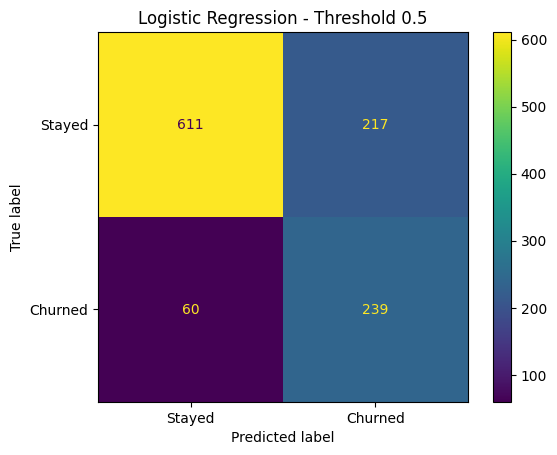

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

selected_threshold = 0.5

y_selected_pred = (
    y_val_prob >= selected_threshold
).astype(int)

cm = confusion_matrix(y_val, y_selected_pred)

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
).plot()

plt.title("Logistic Regression - Threshold 0.5")
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Generate predictions on unseen test data
y_test_pred = lr_model.predict(X_test)
y_test_prob = lr_model.predict_proba(X_test)[:, 1]

# Calculate metrics
print("FINAL MODEL - TEST RESULTS")
print("---------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Precision:", round(precision_score(y_test, y_test_pred), 4))
print("Recall:", round(recall_score(y_test, y_test_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_test_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Stayed", "Churned"]
))

FINAL MODEL - TEST RESULTS
---------------------------
Accuracy: 0.741
Precision: 0.5077
Recall: 0.7888
F1 Score: 0.6178
ROC-AUC: 0.8421

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [ ]:
import joblib
import json
from pathlib import Path

# Create models directory if it doesn't exist
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Save complete trained pipeline
model_path = MODELS_DIR / "logistic_regression.pkl"
joblib.dump(lr_model, model_path)

# Store baseline evaluation metrics
baseline_metrics = {
    "model_name": "Logistic Regression",
    "model_version": "1.0",
    "classification_threshold": 0.5,
    "accuracy": accuracy_score(y_test, y_test_pred),
    "precision": precision_score(y_test, y_test_pred),
    "recall": recall_score(y_test, y_test_pred),
    "f1_score": f1_score(y_test, y_test_pred),
    "roc_auc": roc_auc_score(y_test, y_test_prob)
}

metrics_path = MODELS_DIR / "baseline_metrics.json"

with open(metrics_path, "w") as f:
    json.dump(baseline_metrics, f, indent=4)

print("Model saved:", model_path)
print("Baseline metrics saved:", metrics_path)

Model saved: c:\Users\sharv\Desktop\ModelOps-Sentinel\models\logistic_regression.pkl
Baseline metrics saved: c:\Users\sharv\Desktop\ModelOps-Sentinel\models\baseline_metrics.json


In [ ]:
import joblib

loaded_model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model type:", type(loaded_model))

Model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>


In [ ]:
sample_customer = X_test.iloc[[0]]

prediction = loaded_model.predict(sample_customer)
probability = loaded_model.predict_proba(sample_customer)[0][1]

print("Prediction:", "Churn" if prediction[0] == 1 else "Stay")
print("Churn Probability:", round(probability * 100, 2), "%")

Prediction: Stay
Churn Probability: 10.25 %


In [ ]:
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

print("\nAll model features:")
print(X_train.columns.tolist())

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

All model features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [ ]:
print("X_fit exists:", "X_fit" in globals())

X_fit exists: True


In [ ]:
from pathlib import Path

# Locate project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Create processed data folder
processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

# Save training features as reference data
reference_path = processed_dir / "reference_data.csv"
X_fit.to_csv(reference_path, index=False)

print("Reference dataset saved successfully!")
print("Location:", reference_path)
print("Shape:", X_fit.shape)

Reference dataset saved successfully!
Location: c:\Users\sharv\Desktop\ModelOps-Sentinel\data\processed\reference_data.csv
Shape: (4507, 19)


In [ ]:
import pandas as pd

reference_df = pd.read_csv(reference_path)

print("Reference data shape:", reference_df.shape)
print("Missing values:", reference_df.isnull().sum().sum())
print("Total records:", len(reference_df))
print("Columns:", list(reference_df.columns))

Reference data shape: (4507, 19)
Missing values: 0
Total records: 4507
Columns: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [ ]:
import pandas as pd
from pathlib import Path

# Move one level up from notebooks to project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

production_path = (
    project_root / "data" / "processed" / "production_data.csv"
)

production_df = pd.read_csv(production_path)

print("Production data shape:", production_df.shape)
print("Production records:", len(production_df))
print("Missing values:", production_df.isnull().sum().sum())

production_df.head()

Production data shape: (8, 19)
Production records: 8
Missing values: 0


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod
0,1,1,1200.0,1500.0,Male,Yes,Yes,Yes,Yes,DSL,Yes,Yes,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check
1,1,2,95.5,191.0,Female,No,No,Yes,No,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check
2,0,65,65.2,4238.0,Male,Yes,Yes,Yes,Yes,DSL,Yes,Yes,Yes,Yes,No,No,Two year,No,Bank transfer (automatic)
3,1,0,0.0,0.0,Male,Yes,Yes,Yes,Yes,DSL,Yes,Yes,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check
4,0,0,0.0,0.0,Male,Yes,Yes,Yes,Yes,DSL,Yes,Yes,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check


In [ ]:
import pandas as pd
from pathlib import Path

# Locate project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Load reference data
reference_path = project_root / "data" / "processed" / "reference_data.csv"
reference_df = pd.read_csv(reference_path)

# Select customers with shorter tenure to simulate a shift
short_tenure = reference_df[reference_df["tenure"] <= 12]

# Generate 500 simulated production records
simulated_df = short_tenure.sample(
    n=500,
    replace=True,
    random_state=42
).copy()

# Save separately — don't overwrite actual production logs
simulated_path = (
    project_root / "data" / "processed" / "simulated_production_data.csv"
)

simulated_df.to_csv(simulated_path, index=False)

print("Simulated production data created!")
print("Shape:", simulated_df.shape)
print("Average reference tenure:", reference_df["tenure"].mean())
print("Average simulated tenure:", simulated_df["tenure"].mean())
print("Saved at:", simulated_path)

Simulated production data created!
Shape: (500, 19)
Average reference tenure: 32.29642777901043
Average simulated tenure: 4.632
Saved at: c:\Users\sharv\Desktop\ModelOps-Sentinel\data\processed\simulated_production_data.csv


In [ ]:
import pandas as pd

# Compare numeric features
numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

comparison = pd.DataFrame({
    "Reference Mean": reference_df[numeric_columns].mean(),
    "Production Mean": simulated_df[numeric_columns].mean(),
    "Reference Std": reference_df[numeric_columns].std(),
    "Production Std": simulated_df[numeric_columns].std()
})

comparison["Mean Difference"] = (
    comparison["Production Mean"] - comparison["Reference Mean"]
)

comparison

,Reference Mean,Production Mean,Reference Std,Production Std,Mean Difference
tenure,32.296428,4.6320,24.656729,3.626966,-27.664428
MonthlyCharges,64.695341,54.7046,30.017857,26.783192,-9.990741
TotalCharges,2283.093199,263.6460,2279.035508,260.699865,-2019.447199


In [ ]:
from scipy.stats import ks_2samp

numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

for column in numeric_columns:

    result = ks_2samp(
        reference_df[column],
        simulated_df[column]
    )

    print(f"\nFeature: {column}")
    print(f"KS Statistic: {result.statistic:.4f}")
    print(f"P-value: {result.pvalue:.6f}")

    if result.pvalue < 0.05:
        print("Result: Potential Drift Detected")
    else:
        print("Result: No statistically significant drift")


Feature: tenure
KS Statistic: 0.6865
P-value: 0.000000
Result: Potential Drift Detected

Feature: MonthlyCharges
KS Statistic: 0.1777
P-value: 0.000000
Result: Potential Drift Detected

Feature: TotalCharges
KS Statistic: 0.5871
P-value: 0.000000
Result: Potential Drift Detected


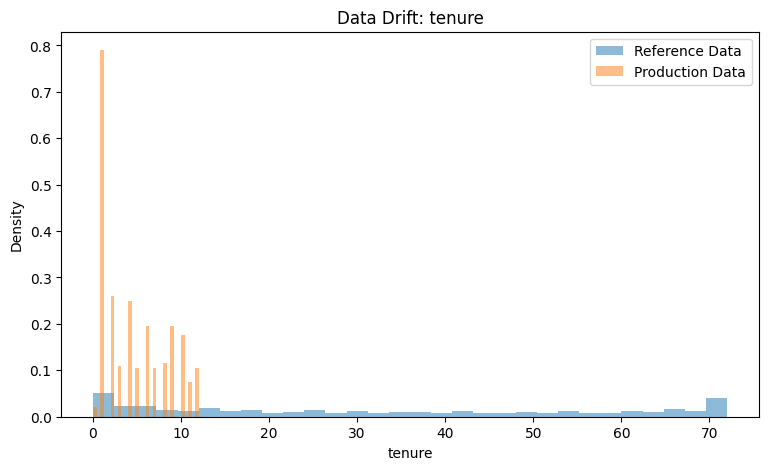

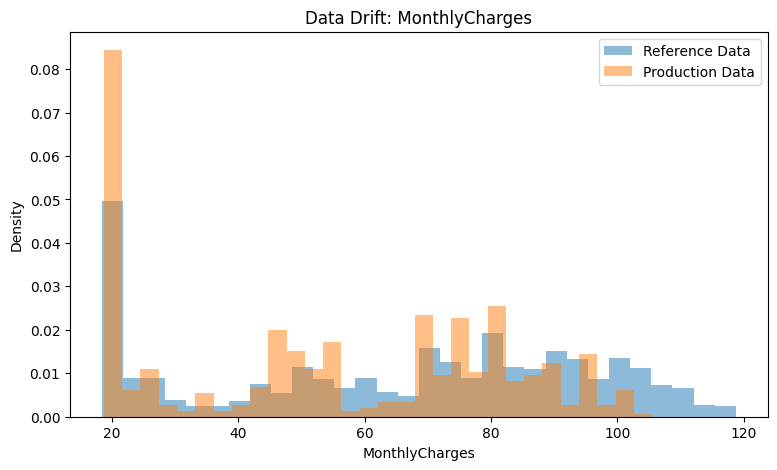

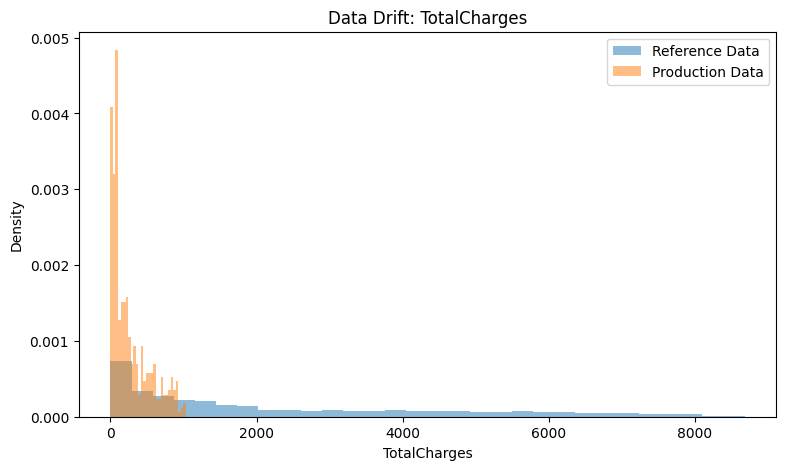

In [ ]:
import matplotlib.pyplot as plt

numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

for column in numeric_columns:

    plt.figure(figsize=(9, 5))

    plt.hist(
        reference_df[column],
        bins=30,
        alpha=0.5,
        density=True,
        label="Reference Data"
    )

    plt.hist(
        simulated_df[column],
        bins=30,
        alpha=0.5,
        density=True,
        label="Production Data"
    )

    plt.title(f"Data Drift: {column}")
    plt.xlabel(column)
    plt.ylabel("Density")
    plt.legend()
    plt.show()

In [ ]:
from scipy.stats import chi2_contingency
import pandas as pd

categorical_columns = [
    "InternetService",
    "Contract",
    "PaymentMethod"
]

for column in categorical_columns:

    # Count category frequencies
    reference_counts = reference_df[column].value_counts()
    production_counts = simulated_df[column].value_counts()

    # Align categories across both datasets
    contingency_table = pd.DataFrame({
        "Reference": reference_counts,
        "Production": production_counts
    }).fillna(0)

    # Run Chi-Square test
    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table.T
    )

    print(f"\nFeature: {column}")
    print(f"Chi-Square Statistic: {chi2:.4f}")
    print(f"P-value: {p_value:.6f}")

    if p_value < 0.05:
        print("Result: Potential Drift Detected")
    else:
        print("Result: No statistically significant drift")


Feature: InternetService
Chi-Square Statistic: 6.2417
P-value: 0.044120
Result: Potential Drift Detected

Feature: Contract
Chi-Square Statistic: 260.3177
P-value: 0.000000
Result: Potential Drift Detected

Feature: PaymentMethod
Chi-Square Statistic: 123.3174
P-value: 0.000000
Result: Potential Drift Detected


In [ ]:
from scipy.stats import chi2_contingency

# Automatically identify categorical columns
categorical_columns = reference_df.select_dtypes(
    include=["object"]
).columns.tolist()

categorical_results = []

for column in categorical_columns:

    reference_counts = reference_df[column].value_counts()
    production_counts = simulated_df[column].value_counts()

    contingency_table = pd.DataFrame({
        "Reference": reference_counts,
        "Production": production_counts
    }).fillna(0)

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table.T
    )

    categorical_results.append({
        "Feature": column,
        "Chi_Square": chi2,
        "P_Value": p_value,
        "Drift_Detected": p_value < 0.05
    })

categorical_drift_report = pd.DataFrame(categorical_results)

categorical_drift_report

C:\Users\sharv\AppData\Local\Temp\ipykernel_14864\3503444839.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = reference_df.select_dtypes(


,Feature,Chi_Square,P_Value,Drift_Detected
0,gender,0.953013,3.289535e-01,False
1,Partner,114.874756,8.382813e-27,True
2,Dependents,12.789076,3.486493e-04,True
3,PhoneService,0.945648,3.308297e-01,False
4,MultipleLines,124.893123,7.582336e-28,True
5,InternetService,6.241668,4.412036e-02,True
6,OnlineSecurity,50.799925,9.309718e-12,True
7,OnlineBackup,78.982967,7.064260e-18,True
8,DeviceProtection,86.024364,2.089520e-19,True
9,TechSupport,84.737162,3.977033e-19,True


In [ ]:
from scipy.stats import ks_2samp, chi2_contingency
import pandas as pd

# Continuous numerical features
numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# All remaining features, including SeniorCitizen
categorical_columns = [
    col for col in reference_df.columns
    if col not in numeric_columns
]

drift_results = []

# Numerical drift: KS test
for column in numeric_columns:

    result = ks_2samp(
        reference_df[column],
        simulated_df[column]
    )

    drift_results.append({
        "Feature": column,
        "Test": "KS Test",
        "Statistic": result.statistic,
        "P_Value": result.pvalue
    })


# Categorical drift: Chi-Square test
for column in categorical_columns:

    ref_counts = reference_df[column].value_counts()
    prod_counts = simulated_df[column].value_counts()

    contingency_table = pd.DataFrame({
        "Reference": ref_counts,
        "Production": prod_counts
    }).fillna(0)

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table.T
    )

    drift_results.append({
        "Feature": column,
        "Test": "Chi-Square",
        "Statistic": chi2,
        "P_Value": p_value
    })


# Unified report
drift_report = pd.DataFrame(drift_results)

# Bonferroni correction
alpha = 0.05
adjusted_threshold = alpha / len(drift_report)

drift_report["Drift_Detected"] = (
    drift_report["P_Value"] < adjusted_threshold
)

print("Total features monitored:", len(drift_report))
print("Adjusted threshold:", adjusted_threshold)
print("Potential drift:", drift_report["Drift_Detected"].sum())

drift_report.sort_values(
    "P_Value"
).reset_index(drop=True)

Total features monitored: 19
Adjusted threshold: 0.002631578947368421
Potential drift: 14


,Feature,Test,Statistic,P_Value,Drift_Detected
0,tenure,KS Test,0.686488,3.161973e-208,True
1,TotalCharges,KS Test,0.587068,1.111797e-146,True
2,Contract,Chi-Square,260.317666,2.969868e-57,True
3,MultipleLines,Chi-Square,124.893123,7.582336e-28,True
4,Partner,Chi-Square,114.874756,8.382813e-27,True
5,PaymentMethod,Chi-Square,123.317380,1.489029e-26,True
6,DeviceProtection,Chi-Square,86.024364,2.089520e-19,True
7,TechSupport,Chi-Square,84.737162,3.977033e-19,True
8,OnlineBackup,Chi-Square,78.982967,7.064260e-18,True
9,StreamingTV,Chi-Square,67.295890,2.437155e-15,True


In [ ]:
import sys
from pathlib import Path

# Locate project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Add project root to Python import path
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)
print("Monitoring folder exists:", (project_root / "monitoring").exists())

Project root: c:\Users\sharv\Desktop\ModelOps-Sentinel
Monitoring folder exists: True


In [ ]:
from monitoring.drift_detector import detect_data_drift

print("Drift detector imported successfully!")

Drift detector imported successfully!


In [ ]:
from monitoring.drift_detector import detect_data_drift

# Run drift detection
drift_report = detect_data_drift(
    reference_df,
    simulated_df
)

# Display results
print("Drift detection completed!")
print("Total features:", len(drift_report))
print("Potential drift:", drift_report["Drift_Detected"].sum())

drift_report

Drift detection completed!
Total features: 19
Potential drift: 14


,Feature,Test,Statistic,P_Value,Effect_Size,Expected_Min,Test_Validity,Adjusted_Threshold,Drift_Detected,Severity
0,tenure,KS Test,0.686488,0.0,0.686488,None,Valid,0.002632,True,Critical
1,MonthlyCharges,KS Test,0.177681,0.0,0.177681,None,Valid,0.002632,True,Moderate
2,TotalCharges,KS Test,0.587068,0.0,0.587068,None,Valid,0.002632,True,Critical
3,gender,Chi-Square,0.953013,0.328953,0.013796,246.854404,Valid,0.002632,False,None
4,SeniorCitizen,Chi-Square,4.055125,0.044037,0.028459,79.089275,Valid,0.002632,False,None
5,Partner,Chi-Square,114.874756,0.0,0.151469,228.779708,Valid,0.002632,True,Moderate
6,Dependents,Chi-Square,12.789076,0.000349,0.050539,145.995606,Valid,0.002632,True,Low
7,PhoneService,Chi-Square,0.945648,0.33083,0.013743,50.728979,Valid,0.002632,False,None
8,MultipleLines,Chi-Square,124.893123,0.0,0.157936,50.728979,Valid,0.002632,True,Moderate
9,InternetService,Chi-Square,6.241668,0.04412,0.035307,110.045936,Valid,0.002632,False,None


In [ ]:
import importlib
import monitoring.drift_detector

importlib.reload(monitoring.drift_detector)

from monitoring.drift_detector import detect_data_drift

In [ ]:
from monitoring.drift_detector import detect_data_drift

drift_report = detect_data_drift(
    reference_df,
    simulated_df
)

print("MONITORING ENGINE REPORT")
print("------------------------")

print("Total features:", len(drift_report))
print(
    "Drifted features:",
    int(drift_report["Drift_Detected"].sum())
)

display(
    drift_report.sort_values(
        by="P_Value"
    )
)

MONITORING ENGINE REPORT
------------------------
Total features: 19
Drifted features: 14


,Feature,Test,Statistic,P_Value,Effect_Size,Expected_Min,Test_Validity,Adjusted_Threshold,Drift_Detected,Severity
0,tenure,KS Test,0.686488,0.0,0.686488,None,Valid,0.002632,True,Critical
2,TotalCharges,KS Test,0.587068,0.0,0.587068,None,Valid,0.002632,True,Critical
16,Contract,Chi-Square,260.317666,0.0,0.228015,93.868584,Valid,0.002632,True,High
8,MultipleLines,Chi-Square,124.893123,0.0,0.157936,50.728979,Valid,0.002632,True,Moderate
5,Partner,Chi-Square,114.874756,0.0,0.151469,228.779708,Valid,0.002632,True,Moderate
18,PaymentMethod,Chi-Square,123.31738,0.0,0.156936,100.259637,Valid,0.002632,True,Moderate
12,DeviceProtection,Chi-Square,86.024364,0.0,0.131076,110.045936,Valid,0.002632,True,Moderate
13,TechSupport,Chi-Square,84.737162,0.0,0.130091,110.045936,Valid,0.002632,True,Moderate
11,OnlineBackup,Chi-Square,78.982967,0.0,0.125597,110.045936,Valid,0.002632,True,Moderate
14,StreamingTV,Chi-Square,67.29589,0.0,0.115933,110.045936,Valid,0.002632,True,Moderate


In [ ]:
severity_counts = drift_report["Severity"].value_counts()

critical = severity_counts.get("Critical", 0)
high = severity_counts.get("High", 0)
moderate = severity_counts.get("Moderate", 0)
low = severity_counts.get("Low", 0)

if critical > 0:
    health_status = "CRITICAL"
elif high > 0 or moderate > 0:
    health_status = "DEGRADED"
elif low > 0:
    health_status = "WARNING"
else:
    health_status = "HEALTHY"

print("MODEL HEALTH SUMMARY")
print("--------------------")
print("Overall Status:", health_status)
print("Total Features:", len(drift_report))
print("Drifted Features:", int(drift_report["Drift_Detected"].sum()))
print("Critical:", critical)
print("High:", high)
print("Moderate:", moderate)
print("Low:", low)
print("No Drift:", int((drift_report["Severity"] == "None").sum()))

MODEL HEALTH SUMMARY
--------------------
Overall Status: CRITICAL
Total Features: 19
Drifted Features: 14
Critical: 2
High: 1
Moderate: 9
Low: 2
No Drift: 5


In [ ]:
import sys
import importlib
import joblib
from pathlib import Path

# Locate project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Load the saved ML model
model_path = project_root / "models" / "logistic_regression.pkl"
model = joblib.load(model_path)

# Import the new monitoring module
import monitoring.prediction_monitor
importlib.reload(monitoring.prediction_monitor)

from monitoring.prediction_monitor import monitor_prediction_distribution

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
prediction_report = monitor_prediction_distribution(
    model=model,
    reference_df=reference_df,
    production_df=simulated_df
)

print("PREDICTION DISTRIBUTION MONITORING")
print("----------------------------------")

print("\nREFERENCE DATA:")
print(prediction_report["reference"])

print("\nPRODUCTION DATA:")
print(prediction_report["production"])

print("\nCHURN RATE CHANGE:")
print(
    prediction_report[
        "churn_rate_change_percentage_points"
    ],
    "percentage points"
)

print("\nCLASS DISTRIBUTION:")
print(prediction_report["class_distribution"])

print("\nPROBABILITY DISTRIBUTION:")
print(prediction_report["probability_distribution"])

PREDICTION DISTRIBUTION MONITORING
----------------------------------

REFERENCE DATA:
{'total_predictions': 4507, 'stay_predictions': 2643, 'churn_predictions': 1864, 'churn_rate': 0.4135788773019747}

PRODUCTION DATA:
{'total_predictions': 500, 'stay_predictions': 165, 'churn_predictions': 335, 'churn_rate': 0.67}

CHURN RATE CHANGE:
25.642112269802535 percentage points

CLASS DISTRIBUTION:
{'chi_square_statistic': 119.11023973015824, 'p_value': 9.906790205735373e-28, 'drift_detected': True, 'minimum_expected_count': 219.592570401438}

PROBABILITY DISTRIBUTION:
{'ks_statistic': 0.3489070335034391, 'p_value': 2.3715814645836833e-49, 'drift_detected': True}


In [ ]:
import sys
import importlib
import monitoring.performance_monitor

importlib.reload(monitoring.performance_monitor)

from monitoring.performance_monitor import monitor_model_performance

# Generate predictions on held-out test data
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate performance metrics
performance_report = monitor_model_performance(
    y_true=y_test,
    y_pred=y_pred,
    y_prob=y_prob
)

print("MODEL PERFORMANCE REPORT")
print("-------------------------")

for metric, value in performance_report.items():
    print(f"{metric}: {value}")

MODEL PERFORMANCE REPORT
-------------------------
total_samples: 1409
accuracy: 0.7409510290986515
precision: 0.5077452667814114
recall: 0.7887700534759359
f1_score: 0.6178010471204188
roc_auc: 0.8421142369991474
confusion_matrix: {'true_negative': 749, 'false_positive': 286, 'false_negative': 79, 'true_positive': 295}


In [ ]:
import json
from pathlib import Path

baseline_path = (
    project_root / "models" / "baseline_metrics.json"
)

with open(baseline_path, "r") as file:
    baseline_metrics = json.load(file)

print("BASELINE METRICS")
print("----------------")
print(json.dumps(baseline_metrics, indent=4))

BASELINE METRICS
----------------
{
    "model_name": "Logistic Regression",
    "model_version": "1.0",
    "classification_threshold": 0.5,
    "accuracy": 0.7409510290986515,
    "precision": 0.5077452667814114,
    "recall": 0.7887700534759359,
    "f1_score": 0.6178010471204188,
    "roc_auc": 0.8421142369991474
}


In [ ]:
import importlib
import monitoring.performance_monitor

importlib.reload(monitoring.performance_monitor)

from monitoring.performance_monitor import (
    monitor_model_performance,
    detect_performance_degradation
)

degradation_report = detect_performance_degradation(
    current_metrics=performance_report,
    baseline_metrics=baseline_metrics
)

print("PERFORMANCE DEGRADATION REPORT")
print("--------------------------------")

display(pd.DataFrame(degradation_report))

PERFORMANCE DEGRADATION REPORT
--------------------------------


,Metric,Baseline,Current,Degradation,Severity,Status
0,accuracy,0.740951,0.740951,0.0,None,No Degradation
1,precision,0.507745,0.507745,0.0,None,No Degradation
2,recall,0.788770,0.788770,0.0,None,No Degradation
3,f1_score,0.617801,0.617801,0.0,None,No Degradation
4,roc_auc,0.842114,0.842114,0.0,None,No Degradation


In [ ]:
# Simulate degraded model performance
simulated_metrics = {
    "accuracy": 0.68,
    "precision": 0.44,
    "recall": 0.70,
    "f1_score": 0.54,
    "roc_auc": 0.76
}

degraded_report = detect_performance_degradation(
    current_metrics=simulated_metrics,
    baseline_metrics=baseline_metrics
)

print("SIMULATED DEGRADATION TEST")
print("--------------------------")

display(pd.DataFrame(degraded_report))

SIMULATED DEGRADATION TEST
--------------------------


,Metric,Baseline,Current,Degradation,Severity,Status
0,accuracy,0.740951,0.68,0.060951,High,High Degradation
1,precision,0.507745,0.44,0.067745,High,High Degradation
2,recall,0.788770,0.70,0.088770,High,High Degradation
3,f1_score,0.617801,0.54,0.077801,High,High Degradation
4,roc_auc,0.842114,0.76,0.082114,High,High Degradation


In [ ]:
from pathlib import Path
import pandas as pd

# Combine test features and actual labels
test_df = X_test.copy()

test_df["Churn"] = y_test.values

# Save test dataset
test_path = (
    project_root / "data" / "processed" / "test_data.csv"
)

test_df.to_csv(test_path, index=False)

print("Test dataset saved successfully!")
print("Shape:", test_df.shape)
print("Location:", test_path)

Test dataset saved successfully!
Shape: (1409, 20)
Location: c:\Users\sharv\Desktop\ModelOps-Sentinel\data\processed\test_data.csv


In [ ]:
test_df = pd.read_csv(
    project_root / "data" / "processed" / "test_data.csv"
)

print("Shape:", test_df.shape)
print("Columns:", len(test_df.columns))
print("Target values:", test_df["Churn"].value_counts().to_dict())

Shape: (1409, 20)
Columns: 20
Target values: {0: 1035, 1: 374}
